<a href="https://colab.research.google.com/github/pedroabsouza/colab_ad05/blob/main/api/cat_dog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-API.drawio.png)

# 🐶🐱 Versão 2: várias imagens
Pede às duas APIs várias imagens de uma vez e salva cada uma com um nome diferente (dog_1, dog_2, cat_1, cat_2...) em imagens/multiplas/.

> No Colab os arquivos ficam em /content e são apagados quando a sessão termina. Baixe o que quiser guardar pelo painel de arquivos (ícone de pasta, à esquerda).

> ✍️ Atenção: algumas linhas estão incompletas. Substitua cada ___ para completar o código, nas linhas marcadas com # complete esta linha.

## 1. Importações

In [3]:
import os
import requests
from IPython.display import Image, display

QUANTIDADE = 5

pasta = os.path.join(os.getcwd(), 'imagens/multiplas')
os.makedirs(pasta, exist_ok=True)

## 2. Pasta de saída

In [7]:
def salvar(img_url, nome):
    """Baixa a imagem e salva na pasta com o nome (mantém a extensão original)."""
    extensao = os.path.splitext(img_url)[1] or '.jpg'
    caminho = os.path.join(pasta, nome + extensao)
    img_data = requests.get(img_url).content
    with open(caminho, 'wb') as handler:
        handler.write(img_data)
    print(f"Salvo: {caminho}")
    return caminho

## 3. Requisição à API e download da imagem

In [23]:
caminhos_caes = [] # Cria lista vazia onde imagens serão guardadas
resposta = requests.get(f'https://dog.ceo/api/breeds/image/random/{QUANTIDADE}')  # Envia uma requisição HTTP à API dog.ceo solicitando um determinado número de imagens ALEATÓRIAS definido pela variável QUANTIDADE
for i, img_url in enumerate(resposta.json()['message'], start=1):  # Percorre a lista de imagens
    caminhos_caes.append(salvar(img_url, f'dog{i}'))  # Chama a função salvar passando o link da imagem e nome do ficheiro que será guardado (dog1, dog2), adicionando-a a lista criada no ínicio

print('Pronto!')


Salvo: /content/imagens/multiplas/dog1.jpg
Salvo: /content/imagens/multiplas/dog2.jpg
Salvo: /content/imagens/multiplas/dog3.jpg
Salvo: /content/imagens/multiplas/dog4.jpg
Salvo: /content/imagens/multiplas/dog5.jpg
Pronto!


## 4. Visualizar a imagem

dog1.jpg


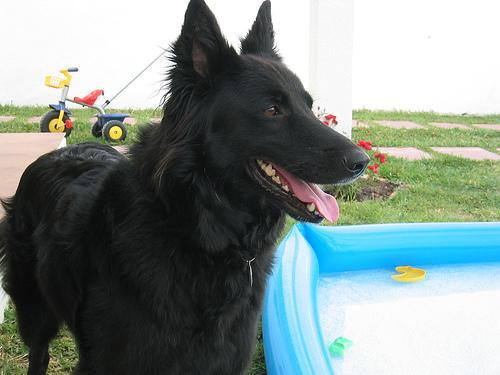

dog2.jpg


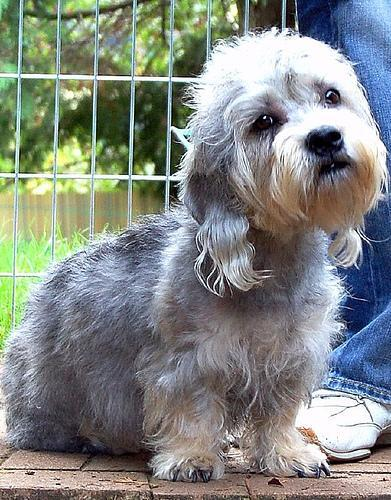

dog3.jpg


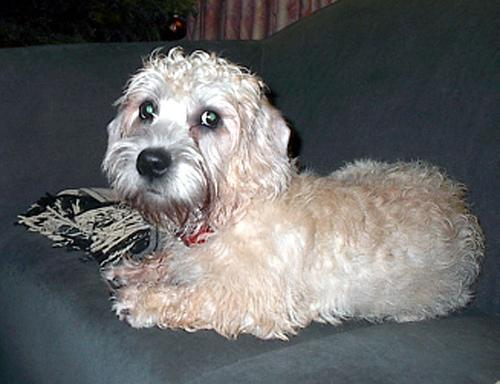

dog4.jpg


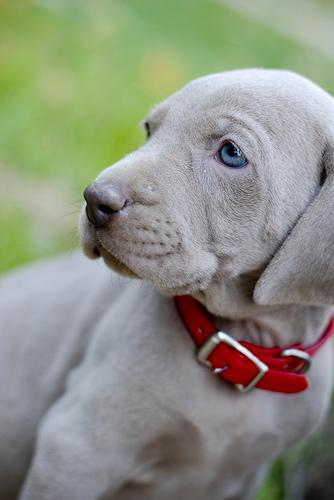

dog5.jpg


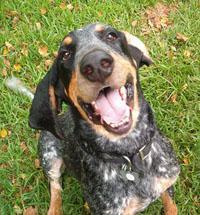

cat_1.jpg


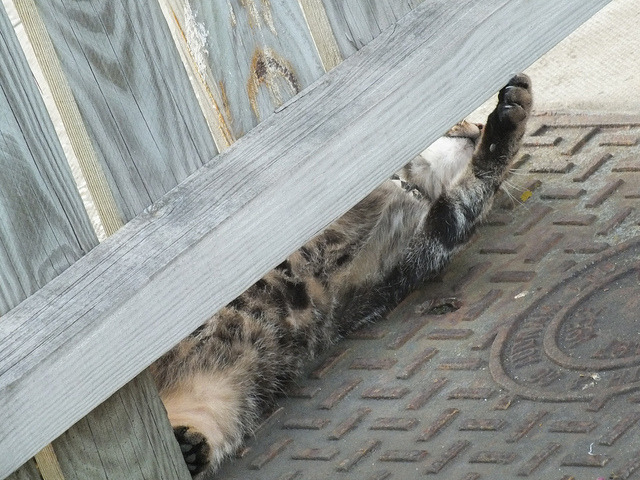

cat_2.jpg


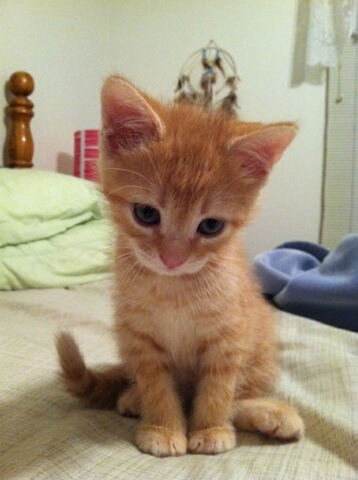

cat_3.jpg


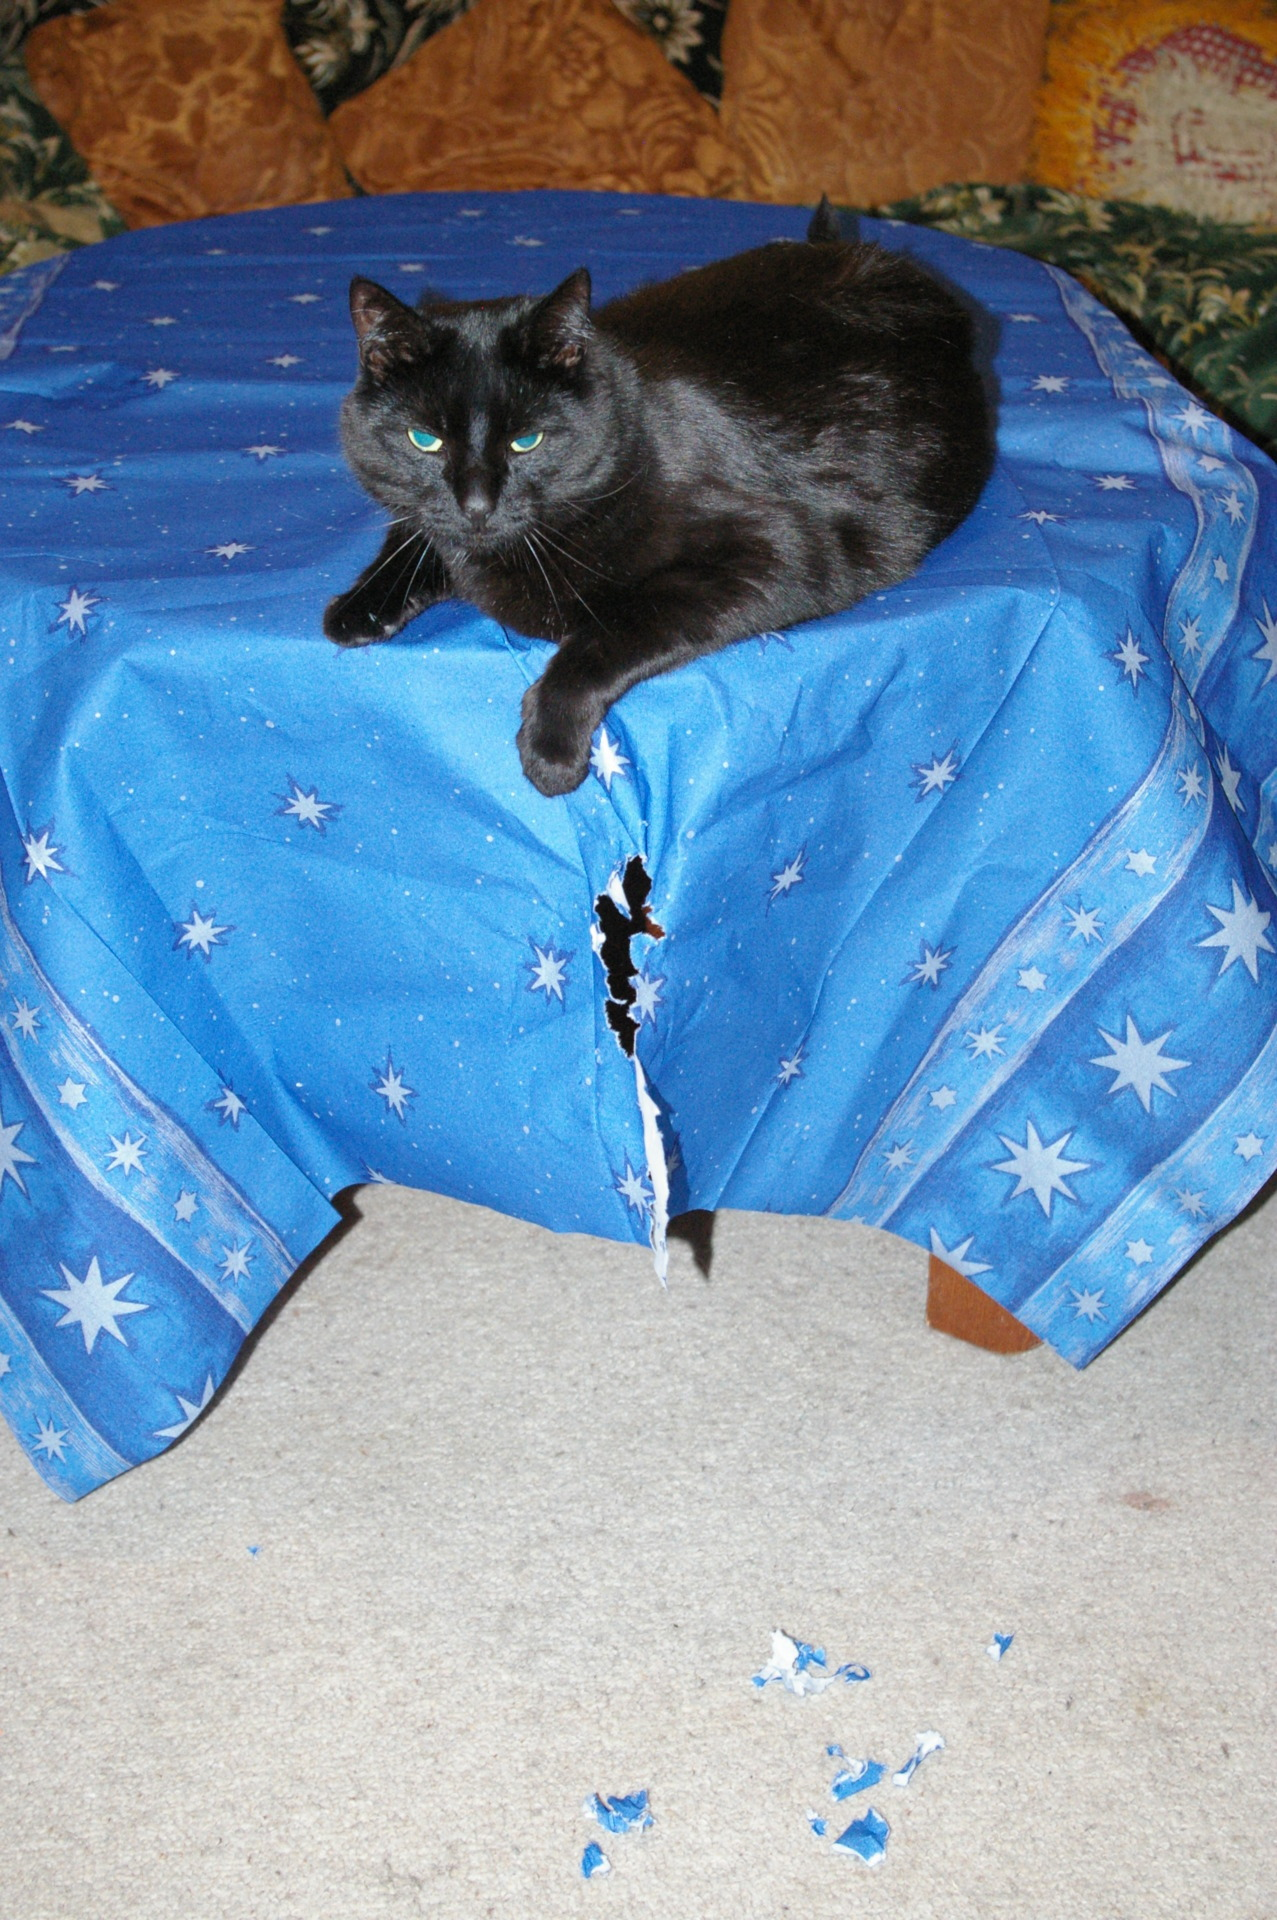

cat_4.jpg


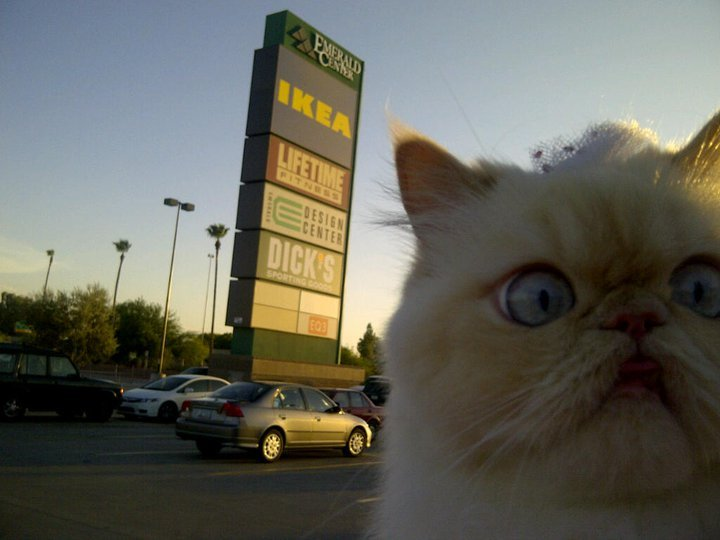

cat_5.jpg


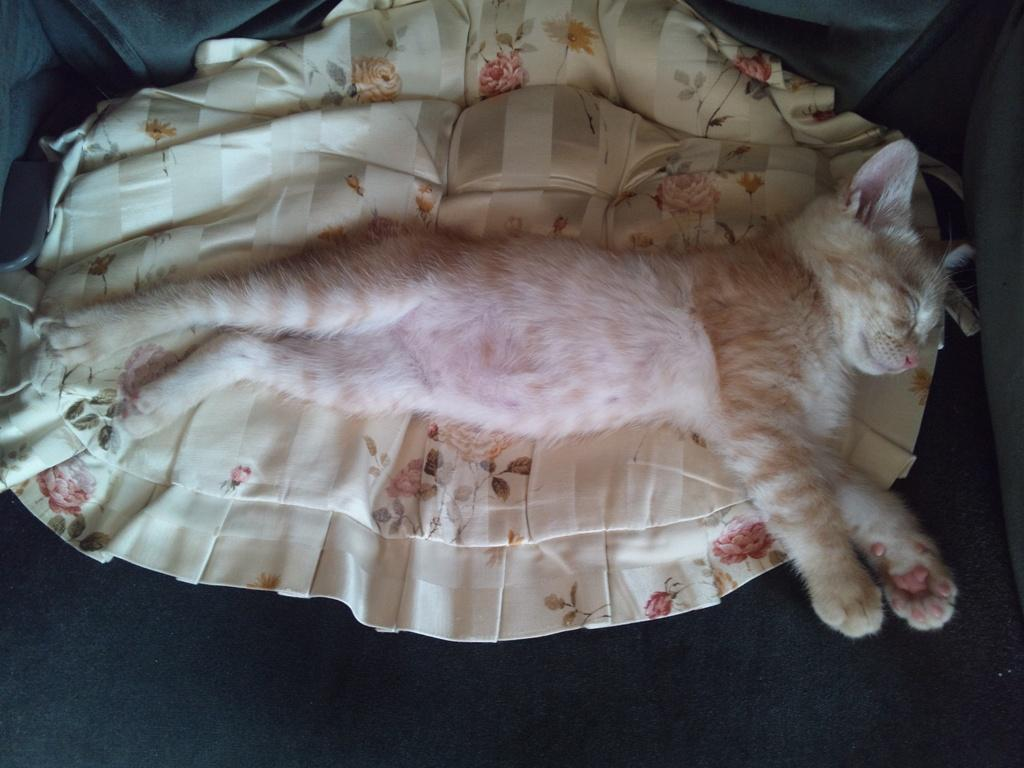

In [24]:
for c in caminhos_caes + caminhos_gatos:
    print(os.path.basename(c))
    display(Image(filename=c, width=250))